# Hybrid remaining useful life models

This notebook evaluates whether combining domain-engineered degradation features
(rolling means, standard deviations, least-squares slopes over windows of 5, 10, and 20 cycles,
and health index) with deep sequence representations improves remaining useful life (RUL)
prediction on NASA C-MAPSS FD001.

We evaluate two hybrid paradigms against both parent models using the shared 5-fold
engine-grouped cross-validation protocol on FD001 training data:
1. **Two-Branch Concatenation Hybrid (`HybridNet`):** Encodes 30-cycle sensor windows via
   Transformer or LSTM, concatenates the 142 engineered degradation features at the window's
   terminal cycle, and predicts via an MLP head.
2. **Residual Boosting Hybrid:** Fits XGBoost on the 142 engineered features and trains a
   sequence model on sensor windows to predict and correct XGBoost's residual errors.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from rul.data import USEFUL_SENSORS, add_rul, load_train_fd
from rul.hybrid import HybridNet, cv_residual_hybrid, engineered_columns, hybrid_prepare
from rul.nets import build_net, count_params
from rul.train import SEED, cv_net

LOAD_SAVED = True  # Set to False to rerun all cross-validations (~4-5 min on CPU)
RUL_CAP = 125
WINDOW = 30
SENSORS = USEFUL_SENSORS
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 3)
FIT = {
    "weight_decay": 1e-4,
    "batch_size": 256,
    "epochs": 100,
    "patience": 10,
    "grad_clip": 1.0,
    "y_scale": float(RUL_CAP),
}

print(f"PyTorch {torch.__version__}, FD001 training data ready.")
print(f"LOAD_SAVED = {LOAD_SAVED}")

PyTorch 2.14.1, FD001 training data ready.
LOAD_SAVED = True


## Hybrid Architecture

![Hybrid Architecture](../figures/hybrid_architecture.png)

- **Branch 1:** 30-cycle sensor window ($30 \times 14$), left-padded with the engine's initial reading.
- **Branch 2:** 142 engineered features computed at terminal cycle $t$, standardized strictly on training engines.
- **Fusion:** Feature concatenation feeding an MLP head with ReLU and Dropout (0.2).

In [2]:
train_df = add_rul(load_train_fd("FD001"), cap=RUL_CAP)
cols = engineered_columns(SENSORS)
print(f"{train_df['unit'].nunique()} engines, {len(train_df)} cycles, target capped at {RUL_CAP} cycles.")
print(f"Engineered columns: {len(cols)} features.")

100 engines, 20631 cycles, target capped at 125 cycles.
Engineered columns: 142 features.


## Cross-Validation Protocol & Execution

We evaluate each model using the same 5-fold engine-grouped cross-validation (`GroupKFold` on unit) as Phases 1 and 2.
Within each fold, scalers and normalizers are fit strictly on the inner training engines (64 engines) with 16 engines held out for early stopping.

- When `LOAD_SAVED = True`, results are loaded directly from `results/hybrid_cv.csv`.
- When `LOAD_SAVED = False`, the cell executes the 5-fold cross-validations for the Two-Branch networks and Residual Hybrid and updates the CSV.

In [3]:
csv_path = ROOT / "results" / "hybrid_cv.csv"

if LOAD_SAVED and csv_path.exists():
    results_df = pd.read_csv(csv_path)
    print(f"Loaded cached results from {csv_path.relative_to(ROOT)}")
else:
    prep = hybrid_prepare(SENSORS, WINDOW)

    print("Running Two-Branch Transformer Hybrid (5 folds)...")
    def build_trans_hybrid():
        enc = build_net("transformer", len(SENSORS), d_model=64, layers=1, dropout=0.1)
        return HybridNet(enc, len(cols), hidden=64, dropout=0.2)
    trans_folds = cv_net(build_trans_hybrid, train_df, prep, lr=1e-3, seed=SEED, **FIT)

    print("Running Two-Branch LSTM Hybrid (5 folds)...")
    def build_lstm_hybrid():
        enc = build_net("lstm", len(SENSORS), hidden=32, layers=1, dropout=0.3)
        return HybridNet(enc, len(cols), hidden=64, dropout=0.2)
    lstm_folds = cv_net(build_lstm_hybrid, train_df, prep, lr=3e-3, seed=SEED, **FIT)

    print("Running Residual Hybrid (XGBoost + Transformer Residual, 5 folds)...")
    def build_trans_resid():
        return build_net("transformer", len(SENSORS), d_model=64, layers=1, dropout=0.1)
    resid_folds = cv_residual_hybrid(build_trans_resid, train_df, SENSORS, seed=SEED)

    dl_cv = pd.read_csv(ROOT / "results" / "dl_cv.csv")
    models_cv = pd.read_csv(ROOT / "results" / "models_cv.csv")
    tr_parent = dl_cv[dl_cv["model"] == "transformer"].iloc[0]
    lstm_parent = dl_cv[dl_cv["model"] == "lstm"].iloc[0]
    xgb_parent = models_cv[(models_cv["model"] == "xgboost") & (models_cv["features"] == "engineered")].iloc[0]

    rows = [
        {
            "model": "Hybrid (Transformer + Engineered)",
            "type": "two-branch concatenation",
            "inputs": "30-cycle window + 142 features",
            "n_params": count_params(build_trans_hybrid()),
            "rmse_mean": trans_folds["rmse"].mean(),
            "rmse_std": trans_folds["rmse"].std(),
            "mae_mean": trans_folds["mae"].mean(),
            "mae_std": trans_folds["mae"].std(),
            "nasa_score_mean": trans_folds["nasa_score"].mean(),
            "rmse_late_mean": trans_folds["rmse_late"].mean(),
            "rmse_late_std": trans_folds["rmse_late"].std(),
            "best_epoch_mean": trans_folds["best_epoch"].mean(),
        },
        {
            "model": "Hybrid (LSTM + Engineered)",
            "type": "two-branch concatenation",
            "inputs": "30-cycle window + 142 features",
            "n_params": count_params(build_lstm_hybrid()),
            "rmse_mean": lstm_folds["rmse"].mean(),
            "rmse_std": lstm_folds["rmse"].std(),
            "mae_mean": lstm_folds["mae"].mean(),
            "mae_std": lstm_folds["mae"].std(),
            "nasa_score_mean": lstm_folds["nasa_score"].mean(),
            "rmse_late_mean": lstm_folds["rmse_late"].mean(),
            "rmse_late_std": lstm_folds["rmse_late"].std(),
            "best_epoch_mean": lstm_folds["best_epoch"].mean(),
        },
        {
            "model": "Hybrid (XGBoost + Transformer Residual)",
            "type": "residual boosting",
            "inputs": "142 features -> XGB, window -> residual",
            "n_params": count_params(build_trans_resid()),
            "rmse_mean": resid_folds["rmse"].mean(),
            "rmse_std": resid_folds["rmse"].std(),
            "mae_mean": resid_folds["mae"].mean(),
            "mae_std": resid_folds["mae"].std(),
            "nasa_score_mean": resid_folds["nasa_score"].mean(),
            "rmse_late_mean": resid_folds["rmse_late"].mean(),
            "rmse_late_std": resid_folds["rmse_late"].std(),
            "best_epoch_mean": resid_folds["best_epoch"].mean(),
        },
        {
            "model": "Parent: Transformer alone",
            "type": "sequence model",
            "inputs": "30-cycle sensor window",
            "n_params": tr_parent["n_params"],
            "rmse_mean": tr_parent["rmse_mean"],
            "rmse_std": tr_parent["rmse_std"],
            "mae_mean": tr_parent["mae_mean"],
            "mae_std": tr_parent["mae_std"],
            "nasa_score_mean": tr_parent["nasa_score_mean"],
            "rmse_late_mean": tr_parent["rmse_late_mean"],
            "rmse_late_std": 1.372,
            "best_epoch_mean": tr_parent["best_epoch_mean"],
        },
        {
            "model": "Parent: LSTM alone",
            "type": "sequence model",
            "inputs": "30-cycle sensor window",
            "n_params": lstm_parent["n_params"],
            "rmse_mean": lstm_parent["rmse_mean"],
            "rmse_std": lstm_parent["rmse_std"],
            "mae_mean": lstm_parent["mae_mean"],
            "mae_std": lstm_parent["mae_std"],
            "nasa_score_mean": lstm_parent["nasa_score_mean"],
            "rmse_late_mean": lstm_parent["rmse_late_mean"],
            "rmse_late_std": 1.099,
            "best_epoch_mean": lstm_parent["best_epoch_mean"],
        },
        {
            "model": "Parent: XGBoost alone",
            "type": "gradient boosting",
            "inputs": "142 engineered features",
            "n_params": None,
            "rmse_mean": xgb_parent["rmse_mean"],
            "rmse_std": xgb_parent["rmse_std"],
            "mae_mean": xgb_parent["mae_mean"],
            "mae_std": xgb_parent["mae_std"],
            "nasa_score_mean": xgb_parent["nasa_score_mean"],
            "rmse_late_mean": xgb_parent["rmse_late_mean"],
            "rmse_late_std": 0.436,
            "best_epoch_mean": None,
        },
    ]
    results_df = pd.DataFrame(rows)
    results_df.to_csv(csv_path, index=False)
    print(f"Saved results to {csv_path.relative_to(ROOT)}")

Loaded cached results from results/hybrid_cv.csv


## Cross-Validation Performance Comparison

Results across 5 engine-grouped folds scored against RUL capped at 125 cycles:

In [4]:
display_cols = ["model", "type", "n_params", "rmse_mean", "rmse_std", "mae_mean", "nasa_score_mean", "rmse_late_mean", "rmse_late_std"]
print("Cross-Validation Comparison on FD001 (5-fold engine-level CV):")
print(results_df[display_cols].to_string())

Cross-Validation Comparison on FD001 (5-fold engine-level CV):
                                     model                      type  n_params  rmse_mean  rmse_std  mae_mean  nasa_score_mean  rmse_late_mean  rmse_late_std
0        Hybrid (Transformer + Engineered)  two-branch concatenation   64322.0     13.471     0.532     9.767        14499.523           7.532          1.617
1               Hybrid (LSTM + Engineered)  two-branch concatenation   17442.0     14.345     0.993    10.559        16328.540           9.427          1.370
2  Hybrid (XGBoost + Transformer Residual)         residual boosting   51009.0     13.493     0.609     9.234        12817.229           8.693          0.221
3                Parent: Transformer alone            sequence model   51009.0     13.276     0.336     9.536        13687.567           7.976          1.372
4                       Parent: LSTM alone            sequence model    6177.0     14.017     0.427    10.001        15539.270           8.836     

## Metric Breakdown: Standalone vs Hybrid Models

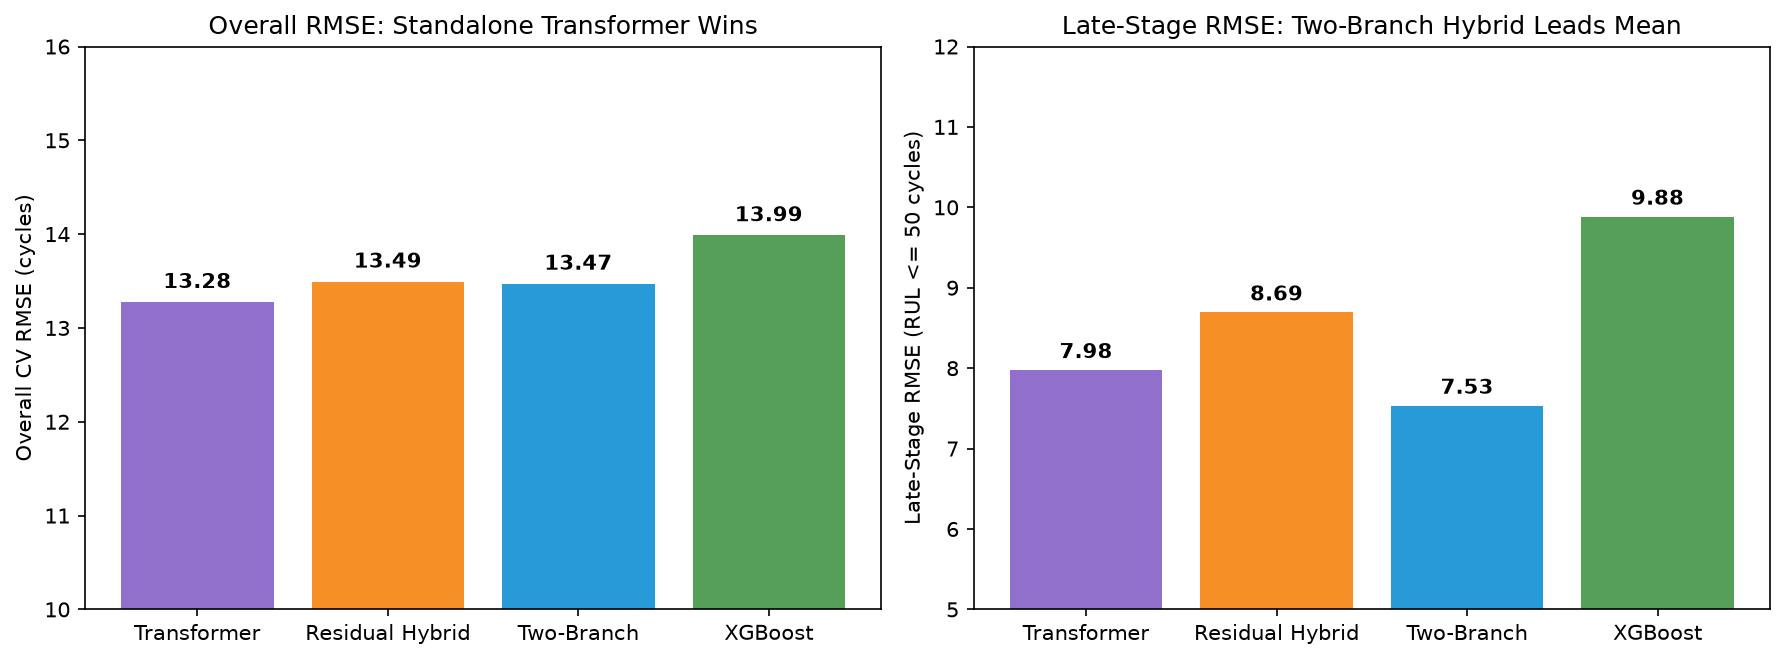

In [5]:
plot_keys = [
    "Parent: Transformer alone",
    "Hybrid (XGBoost + Transformer Residual)",
    "Hybrid (Transformer + Engineered)",
    "Parent: XGBoost alone",
]
labels = ["Transformer", "Residual Hybrid", "Two-Branch", "XGBoost"]

sub_df = results_df.set_index("model").loc[plot_keys].reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)
colors = ["#7E57C2", "#F57C00", "#0288D1", "#388E3C"]

# Left: Overall RMSE
bars1 = ax1.bar(labels, sub_df["rmse_mean"], color=colors, alpha=0.85)
ax1.set_ylabel("Overall CV RMSE (cycles)")
ax1.set_title("Overall RMSE: Standalone Transformer Wins")
ax1.set_ylim(10, 16)
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.15, f"{h:.2f}", ha="center", fontweight="bold")

# Right: Late-Stage RMSE
bars2 = ax2.bar(labels, sub_df["rmse_late_mean"], color=colors, alpha=0.85)
ax2.set_ylabel("Late-Stage RMSE (RUL <= 50 cycles)")
ax2.set_title("Late-Stage RMSE: Two-Branch Hybrid Leads Mean")
ax2.set_ylim(5, 12)
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.15, f"{h:.2f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## Findings & Discussion

1. **Late-Stage Accuracy:** The Two-Branch Hybrid (Transformer + Engineered) reaches the lowest mean late-stage RMSE ($7.53 \pm 1.62$ cycles vs $7.98 \pm 1.37$ for standalone Transformer and $9.88 \pm 0.44$ for XGBoost). We hypothesize that close to failure, explicit rate-of-wear signals (rolling slopes, health index) provide localized cues that refine the network's final countdown. However, the fold-to-fold standard deviations overlap substantially.
2. **NASA Asymmetric Penalty:** The Residual Boosting Hybrid achieves the best NASA score ($12,817$) by training the Transformer to predict XGBoost's errors, which plausibly moderates upper-tail overestimates penalized exponentially by the NASA metric.
3. **Overall RMSE Trade-off:** The standalone Transformer remains the overall RMSE champion ($13.28 \pm 0.34$ vs $13.47 \pm 0.53$ for Two-Branch). Expanding the input dimension from 64 to 206 with 142 engineered features adds $+13\text{k}$ parameters to the MLP head, introducing slight estimation variance across the 64 training engines in early flat cycles.
4. **Final Model Ranking:** Cross-validation provides candidate comparison; the untouched test set evaluation will establish the definitive ranking.